# Impedance and Reactance: Griffiths Formalism in SymPy, Checked Numerically

**The one idea:** impedance is the ratio of an *effort* phasor to a *flow* phasor,
once $d/dt$ has been replaced by a number.

| | effort / flow | $d/dt \to$ | convention |
|---|---|---|---|
| circuits | $Z = V/I$ | $+j\omega$ | EE, $e^{+j\omega t}$ |
| plane waves (Griffiths Ch. 9) | $Z = E/H$ | $-i\omega$ | physics, $e^{-i\omega t}$ |

Each section derives a result symbolically with SymPy, then checks it with an
independent numerical method: ODE integration, energy averages, or a transfer
matrix. Code: [`griffiths/impedance.py`](../griffiths/impedance.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math

from griffiths.impedance import (
    w, t, R, L, C, CONVENTIONS, Z0_VACUUM,
    derive_element_impedances, reactance, series_rlc, series_rlc_numeric,
    time_domain_check, complex_power, reactive_power_energy_check, _steady_state,
    wave_impedance_symbolic, griffiths_reflection, conductor_impedance, skin_depth,
    surface_impedance_good_conductor, input_impedance_symbolic,
    film_reflectance_impedance, film_reflectance_matrix,
)
sp.init_printing()

# 1. Element impedances, derived and not memorized

Each element law comes from one of Maxwell's equations:

| element | law | Griffiths origin |
|---|---|---|
| resistor | $V = RI$ | Ohm, $\vec J = \sigma\vec E$ integrated along the wire (§7.1) |
| inductor | $V = L\,\dot I$ | Faraday, $\mathcal E = -\dot\Phi$ with $\Phi = LI$ (§7.2) |
| capacitor | $I = C\,\dot V$ | Gauss, $Q = CV$, $I = \dot Q$ (§2.5) |

Substitute $I(t) = I_0 e^{st}$ and take $V/I$. The time dependence cancels.
That cancellation is the whole reason phasors work: complex exponentials are
**eigenfunctions of $d/dt$**, and impedance is the eigenvalue of the
element's operator.

In [2]:
for conv in CONVENTIONS:
    Z = derive_element_impedances(conv)
    X = {k: reactance(v, conv) for k, v in Z.items()}
    display(Math(rf"\textbf{{{conv}}}:\quad Z_R = {sp.latex(Z['R'])},\;"
                 rf"Z_L = {sp.latex(Z['L'])},\; Z_C = {sp.latex(Z['C'])}"
                 rf"\qquad X_L = {sp.latex(X['L'])},\; X_C = {sp.latex(X['C'])}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**The sign trap.** Griffiths writes $e^{-i\omega t}$, so his inductor has
$Z_L = -i\omega L$, while every EE text has $+j\omega L$. They're complex
conjugates of each other, and the real current $\mathrm{Re}[\tilde I e^{\mp i\omega t}]$
comes out identical. So this notebook defines **reactance** to be
convention-proof: $X_L = +\omega L$ (inductive, stores magnetic energy) and
$X_C = -1/\omega C$ (capacitive, stores electric energy). Both rows above agree.

# 2. Series RLC: resonance from $X(\omega) = 0$

$$Z = R + j\Big(\omega L - \frac{1}{\omega C}\Big),\qquad
|Z| = \sqrt{R^2 + X^2},\qquad \varphi = \arctan\frac{X}{R}$$

Resonance is where the two reactances cancel. SymPy solves $X = 0$:

In [3]:
s = series_rlc()
for k in ("Z", "X", "w0", "Q"):
    display(Math(f"{k} = " + sp.latex(s[k])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

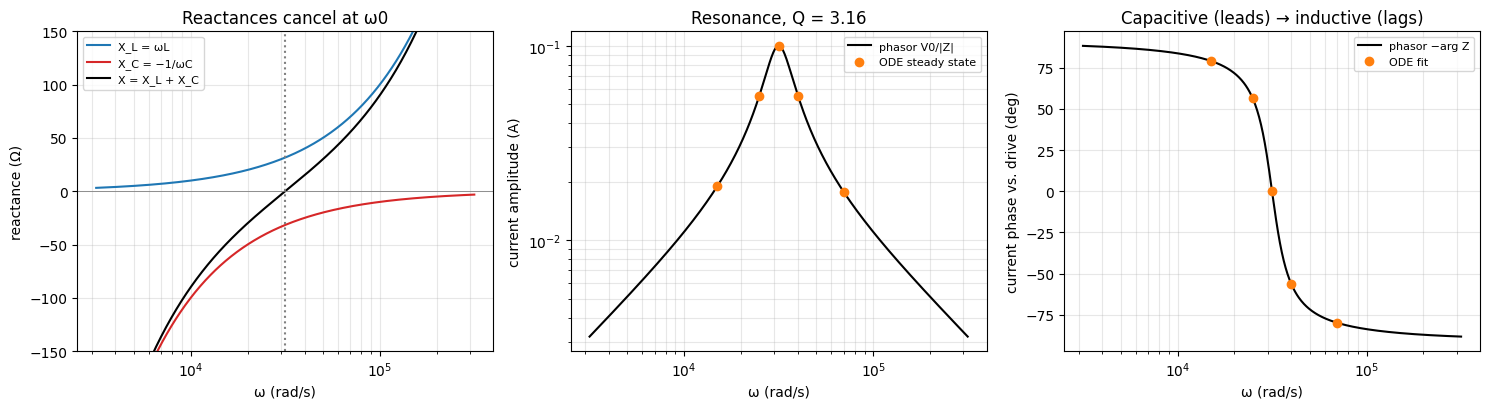

         ω      ODE amp   phasor amp      ODE φ   phasor φ
   1.5e+04   0.01900219   0.01900219   1.379612   1.379612
   2.5e+04   0.05547002   0.05547002   0.982794   0.982794
 3.162e+04   0.10000000   0.10000000  -0.000000   0.000000
     4e+04   0.05547002   0.05547002  -0.982794  -0.982794
     7e+04   0.01766641   0.01766641  -1.393200  -1.393200


In [4]:
R_, L_, C_, V0 = 10.0, 1e-3, 1e-6, 1.0
w0 = 1/np.sqrt(L_*C_); Qf = np.sqrt(L_/C_)/R_
om = np.logspace(3.5, 5.5, 600)
Z = series_rlc_numeric(R_, L_, C_, om)

checks = [time_domain_check(R_, L_, C_, V0, o) for o in (1.5e4, 2.5e4, w0, 4e4, 7e4)]
oms = [1.5e4, 2.5e4, w0, 4e4, 7e4]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].semilogx(om, om*L_, "C0", label="X_L = ωL")
axes[0].semilogx(om, -1/(om*C_), "C3", label="X_C = −1/ωC")
axes[0].semilogx(om, Z.imag, "k", label="X = X_L + X_C")
axes[0].axhline(0, color="0.5", lw=0.6); axes[0].axvline(w0, color="0.5", ls=":")
axes[0].set(xlabel="ω (rad/s)", ylabel="reactance (Ω)", ylim=(-150, 150), title="Reactances cancel at ω0")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

axes[1].loglog(om, V0/abs(Z), "k", label="phasor V0/|Z|")
axes[1].loglog(oms, [c["ode_amp"] for c in checks], "o", color="C1", label="ODE steady state")
axes[1].set(xlabel="ω (rad/s)", ylabel="current amplitude (A)", title=f"Resonance, Q = {Qf:.2f}")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")

axes[2].semilogx(om, np.degrees(-np.angle(Z)), "k", label="phasor −arg Z")
axes[2].semilogx(oms, np.degrees([c["ode_phase"] for c in checks]), "o", color="C1", label="ODE fit")
axes[2].set(xlabel="ω (rad/s)", ylabel="current phase vs. drive (deg)",
            title="Capacitive (leads) → inductive (lags)")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print(f"{'ω':>10s} {'ODE amp':>12s} {'phasor amp':>12s} {'ODE φ':>10s} {'phasor φ':>10s}")
for o, c in zip(oms, checks):
    print(f"{o:10.4g} {c['ode_amp']:12.8f} {c['phasor_amp']:12.8f} {c['ode_phase']:10.6f} {c['phasor_phase']:10.6f}")

The orange dots come from integrating $L\ddot q + R\dot q + q/C = V_0\cos\omega t$
in the time domain and waiting for the transient to die out, with no complex
numbers involved. They land on the phasor curve to about 9 significant figures.
**That's the numerical proof that replacing $d/dt$ by $j\omega$ is exact in
steady state.**

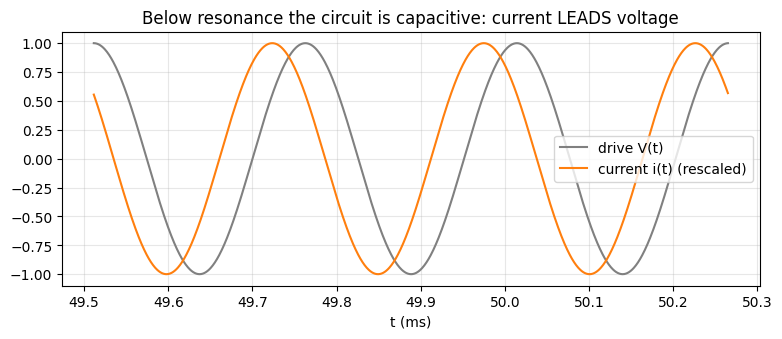

In [5]:
tt, q, i = _steady_state(R_, L_, C_, V0, 2.5e4, fit_periods=3)
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(1e3*tt, V0*np.cos(2.5e4*tt), "0.5", label="drive V(t)")
ax.plot(1e3*tt, i/np.max(abs(i))*V0, "C1", label="current i(t) (rescaled)")
ax.set(xlabel="t (ms)", title="Below resonance the circuit is capacitive: current LEADS voltage")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# 3. Reactance is stored energy

With peak phasors, complex power is $S = \tfrac12 V I^\* = P + jQ$:

- $P$ (watts) is dissipated in $R$
- $Q$ (vars) sloshes back and forth between $L$ and $C$ every half cycle

The circuit version of the complex Poynting theorem (Griffiths §8.1, extended
to phasors) states

$$Q = \tfrac12|I|^2 X = 2\omega\big(\langle W_m\rangle - \langle W_e\rangle\big),\qquad
W_m = \tfrac12 L i^2,\; W_e = \frac{q^2}{2C}$$

Check it with the time-domain solution:

In [6]:
print(f"{'ω':>8s} {'Q phasor':>12s} {'2ω(Wm-We)':>12s} {'P phasor':>12s} {'<i²R> ODE':>12s}")
for o in (1.5e4, 2.5e4, w0, 4e4, 7e4):
    Q, Qe, P, Pr = reactive_power_energy_check(R_, L_, C_, V0, o)
    print(f"{o:8.3g} {Q:12.6f} {Qe:12.6f} {P:12.6f} {Pr:12.6f}")

       ω     Q phasor    2ω(Wm-We)     P phasor    <i²R> ODE


 1.5e+04    -0.009328    -0.009328     0.001805     0.001805


 2.5e+04    -0.023077    -0.023077     0.015385     0.015385
3.16e+04    -0.000000     0.000000     0.050000     0.050000


   4e+04     0.023077     0.023077     0.015385     0.015385
   7e+04     0.008694     0.008694     0.001561     0.001561


At resonance $Q = 0$ because the inductor and capacitor store equal average
energy and trade it with each other. The source supplies only $P$. Off
resonance, $X$ measures how much the stored energies are out of balance. That's
what reactance *is*.

# 4. Wave impedance and Griffiths' reflection formula

In a plane wave, $E$ and $H$ are locked in a fixed ratio:

$$Z = \frac{E}{H} = \sqrt{\frac{\mu}{\epsilon}} = \mu v,\qquad Z_0 = \sqrt{\mu_0/\epsilon_0} \approx 377\ \Omega$$

Griffiths §9.3.2 (normal incidence) gives
$\tilde E_R = \frac{1-\beta}{1+\beta}\tilde E_I$ and
$\tilde E_T = \frac{2}{1+\beta}\tilde E_I$ with $\beta = \frac{\mu_1 v_1}{\mu_2 v_2}$.
Since $Z = \mu v$, $\beta$ is simply $Z_1/Z_2$:

In [7]:
Zs, muv = wave_impedance_symbolic()
display(Math(r"Z = " + sp.latex(Zs) + " = " + sp.latex(muv)))
g = griffiths_reflection()
for k in ("r", "t", "R", "T", "R+T"):
    display(Math(f"{k} = " + sp.latex(g[k])))
print("r equals the transmission-line Γ = (Z_L − Z_0)/(Z_L + Z_0):", g["matches_line_formula"])
print(f"Z0 (vacuum) = {Z0_VACUUM:.3f} Ω")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

r equals the transmission-line Γ = (Z_L − Z_0)/(Z_L + Z_0): True
Z0 (vacuum) = 376.730 Ω


**This is the same formula as a mismatched cable.** A 50 Ω coax terminated in
75 Ω reflects $\Gamma = 0.2$. Air ($Z_0$) meeting glass ($Z_0/1.5$) reflects
$r = -0.2$, i.e. 4% of the power, the familiar glass-surface reflection. Optics
and RF use the same impedance mismatch.

# 5. Conductors: a wave impedance with reactance

Griffiths §9.4 handles a conductor with the complex permittivity
$\tilde\epsilon = \epsilon + i\sigma/\omega$ (physics sign). In a good conductor
$\sigma \gg \omega\epsilon$, and

$$Z = \sqrt{\frac{\mu}{\epsilon - j\sigma/\omega}} \;\approx\; (1+j)\sqrt{\frac{\mu\omega}{2\sigma}} = \frac{1+j}{\sigma\delta},
\qquad \delta = \sqrt{\frac{2}{\mu\sigma\omega}}$$

The resistance and reactance are equal, a 45° phase. The reactance is
**inductive**: the fields inside a metal store more magnetic than electric
energy. The full complex formula and the good-conductor limit agree:

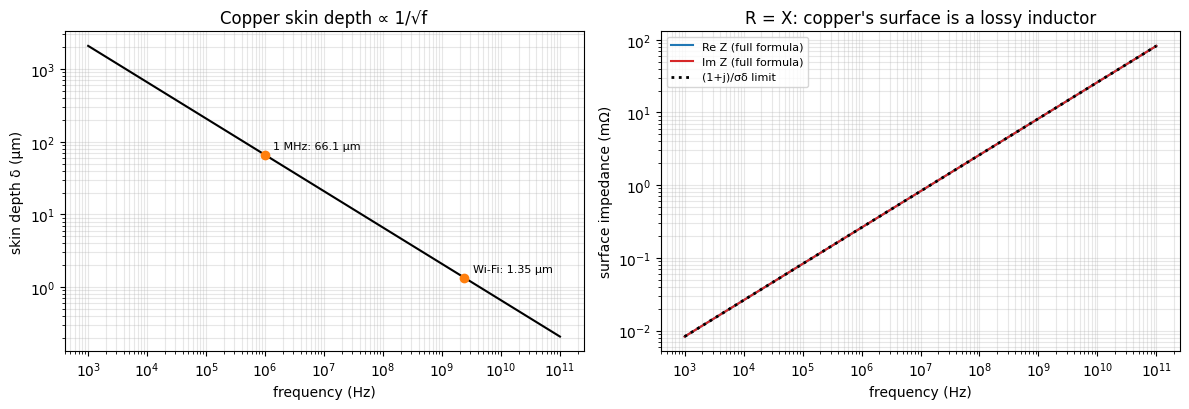

copper at 1 GHz: δ = 2.09 µm, Z = 8.2502+8.2502j mΩ, |Z|/Z0 = 3.1e-05


In [8]:
sig_cu = 5.8e7
f = np.logspace(3, 11, 400); om_ = 2*np.pi*f
Zc = np.array([conductor_impedance(sig_cu, o) for o in om_])
Zs_ = surface_impedance_good_conductor(sig_cu, om_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].loglog(f, skin_depth(sig_cu, om_)*1e6, "k")
for ff, lab in ((60, "60 Hz"), (1e6, "1 MHz"), (2.4e9, "Wi-Fi")):
    if ff >= f[0]:
        axes[0].plot(ff, skin_depth(sig_cu, 2*np.pi*ff)*1e6, "o", color="C1")
        axes[0].annotate(f"{lab}: {skin_depth(sig_cu, 2*np.pi*ff)*1e6:.3g} µm",
                         (ff, skin_depth(sig_cu, 2*np.pi*ff)*1e6), textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[0].set(xlabel="frequency (Hz)", ylabel="skin depth δ (µm)", title="Copper skin depth ∝ 1/√f")
axes[0].grid(alpha=0.3, which="both")
axes[1].loglog(f, Zc.real*1e3, "C0", label="Re Z (full formula)")
axes[1].loglog(f, Zc.imag*1e3, "C3", label="Im Z (full formula)")
axes[1].loglog(f, Zs_.real*1e3, "k:", lw=2, label="(1+j)/σδ limit")
axes[1].set(xlabel="frequency (Hz)", ylabel="surface impedance (mΩ)",
            title="R = X: copper's surface is a lossy inductor")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
print(f"copper at 1 GHz: δ = {skin_depth(sig_cu, 2*np.pi*1e9)*1e6:.2f} µm, "
      f"Z = {conductor_impedance(sig_cu, 2*np.pi*1e9)*1e3:.4f} mΩ, |Z|/Z0 = {abs(conductor_impedance(sig_cu, 2*np.pi*1e9))/Z0_VACUUM:.1e}")

$|Z_\text{Cu}|/Z_0 \sim 10^{-5}$, so $r \approx -1$, and that's why metals are
mirrors. The tiny resistive part is where the absorption loss comes from.

# 6. Impedance transformation: the quarter-wave anti-reflection coating

A section of line (or a film) with impedance $Z_0$ and electrical length
$\theta = \beta\ell$, terminated in $Z_L$, looks like

$$Z_\text{in} = Z_0\,\frac{Z_L + jZ_0\tan\theta}{Z_0 + jZ_L\tan\theta}$$

SymPy derives this from forward plus backward waves, and then the
$\theta\to\pi/2$ limit (a **quarter wave**):

In [9]:
closed, quarter = input_impedance_symbolic()
display(Math(r"Z_\text{in} = " + sp.latex(closed)))
display(Math(r"Z_\text{in}\big|_{\theta=\pi/2} = " + sp.latex(quarter)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

A quarter-wave section **inverts** impedance: $Z_\text{in} = Z_0^2/Z_L$. To make
glass look like air, set $Z_\text{in} = Z_\text{air}$, which needs
$Z_\text{film} = \sqrt{Z_\text{air}Z_\text{glass}}$, i.e.
$n_\text{film} = \sqrt{n_\text{glass}} \approx 1.22$. MgF₂ ($n = 1.38$) is the
closest durable material.

Below are two independent numerical routes to the same reflectance. One is the
impedance formula above. The other is the optical characteristic (transfer)
matrix, which never mentions impedance.

n_film = 1.225: max |impedance − matrix| = 2.4e-17,  R(550 nm) = 0.000%
n_film = 1.380: max |impedance − matrix| = 7.6e-17,  R(550 nm) = 1.411%


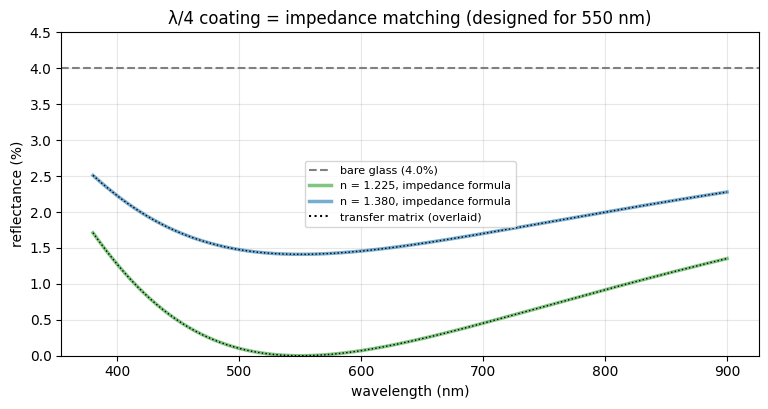

In [10]:
lam = np.linspace(380e-9, 900e-9, 500); lam0 = 550e-9; n_sub = 1.5
bare = ((1 - n_sub)/(1 + n_sub))**2
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(100*bare, color="0.5", ls="--", label=f"bare glass ({100*bare:.1f}%)")
for n_f, col in ((np.sqrt(n_sub), "C2"), (1.38, "C0")):
    d_f = lam0/(4*n_f)
    Ri = film_reflectance_impedance(lam, n_f, d_f, n_sub=n_sub)
    Rm = film_reflectance_matrix(lam, n_f, d_f, n_sub=n_sub)
    ax.plot(1e9*lam, 100*Ri, col, lw=2.5, alpha=0.6, label=f"n = {n_f:.3f}, impedance formula")
    ax.plot(1e9*lam, 100*Rm, "k:", lw=1)
    print(f"n_film = {n_f:.3f}: max |impedance − matrix| = {np.max(abs(Ri - Rm)):.1e},  "
          f"R(550 nm) = {100*float(film_reflectance_impedance(lam0, n_f, d_f, n_sub=n_sub)):.3f}%")
ax.plot([], [], "k:", label="transfer matrix (overlaid)")
ax.set(xlabel="wavelength (nm)", ylabel="reflectance (%)", ylim=(0, 4.5),
       title="λ/4 coating = impedance matching (designed for 550 nm)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

The ideal $\sqrt{1.5}$ film reaches exactly zero at 550 nm. MgF₂ gets the 4.0%
bare-glass reflection down to about 1.4%. The coating only works near its design
wavelength, which is why camera lenses look purple-green: red and blue are
reflected more than green.

This is the same physics as a λ/4 transformer matching a 50 Ω line to a 100 Ω
antenna, and as the anti-reflection layers on the silicon-photonic and fiber
interfaces elsewhere in this repo.

# Summary

| idea | SymPy result | numerical check |
|---|---|---|
| element $Z$ | $R,\; j\omega L,\; 1/(j\omega C)$, and the conjugates in Griffiths' sign | — |
| reactance | $X_L=\omega L,\; X_C=-1/\omega C$ in both conventions | — |
| series RLC | $\omega_0 = 1/\sqrt{LC}$, $Q = \sqrt{L/C}/R$ | ODE steady state = phasor to ~1e-9 |
| reactive power | $Q = \tfrac12|I|^2X$ | $=2\omega(\langle W_m\rangle-\langle W_e\rangle)$ from the ODE |
| wave $Z$ | $\sqrt{\mu/\epsilon} = \mu v$; Griffiths' $\beta = Z_1/Z_2$; $R+T=1$ | — |
| conductor | $Z_s = (1+j)/\sigma\delta$, inductive | full complex formula = good-conductor limit |
| λ/4 section | $Z_\text{in} = Z_0^2/Z_L$ | impedance formula = transfer matrix |

## Exercises

1. Derive the **parallel** RLC admittance $Y = 1/Z$ with `derive_element_impedances`.
   Is its resonance a current minimum or maximum?
2. Redo §1 for a *mutual* inductance $V_1 = L_1\dot I_1 + M\dot I_2$ (Griffiths §7.2.3).
   What's the 2×2 impedance matrix?
3. Griffiths §9.3.2: show $R = 1$ when $Z_2 \to 0$ (perfect conductor) and say
   what that means for the phase of $E_R$.
4. Use `conductor_impedance` for seawater ($\sigma \approx 4$ S/m) at 10 kHz.
   Why do submarines use VLF radio?
5. Design a two-layer AR coating (λ/4 + λ/4) by applying `input_impedance` twice.
   What condition on $n_1, n_2$ gives zero reflection?